 # MNIST Data Preparation, Clustering, and Visualization

 ## 1. Data Preparation and Exploration

In [1]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

 ### Load and Preprocess the MNIST Dataset

In [3]:
# Load the MNIST dataset
print("Fetching MNIST dataset...")
mnist = fetch_openml('mnist_784', version=1, parser='auto')
X = mnist.data
y = mnist.target

print(f"Shape of features (X): {X.shape}")
print(f"Shape of targets (y): {y.shape}")

Fetching MNIST dataset...
Shape of features (X): (70000, 784)
Shape of targets (y): (70000,)


In [4]:
# Normalize the image data to a 0-1 range
# MNIST images are 8-bit grayscale, so pixel values range from 0 to 255.
X_normalized = X / 255.0

print(f"Original min pixel value: {X.min().min()}, max pixel value: {X.max().max()}")
print(f"Normalized min pixel value: {X_normalized.min().min()}, max pixel value: {X_normalized.max().max()}")

Original min pixel value: 0, max pixel value: 255
Normalized min pixel value: 0.0, max pixel value: 1.0


 The dataset is already flattened into vectors (784 features for each 28x28 image). We can proceed with exploration.

 ### Exploratory Data Analysis (EDA)

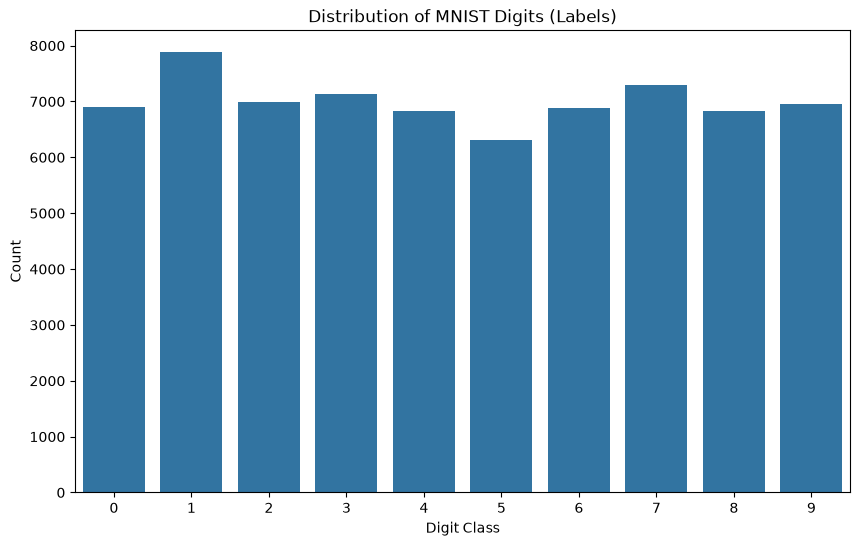

In [6]:
# Check the distribution of labels
plt.figure(figsize=(10, 6))
sns.countplot(x=y)
plt.title('Distribution of MNIST Digits (Labels)')
plt.xlabel('Digit Class')
plt.ylabel('Count')
plt.show()

 ## 2. Clustering

 ### Apply K-Means Clustering

 Given the large size of the MNIST dataset (70,000 samples), performing K-Means on the entire dataset can be computationally intensive. To make the process more manageable for this demonstration, we will apply K-Means to a **subset** of the data. This allows for quicker iteration and visualization, while still demonstrating the clustering principles.

In [7]:
# For practical purposes and faster computation, we'll use a subset of the data.
# For example, let's take the first 10,000 samples.
n_samples_subset = 10000
X_subset = X_normalized[:n_samples_subset]
y_subset = y[:n_samples_subset]

print(f"Using a subset of {n_samples_subset} samples for clustering.")
print(f"Shape of X_subset: {X_subset.shape}")

Using a subset of 10000 samples for clustering.
Shape of X_subset: (10000, 784)


 ### Determine Optimal Number of Clusters (Elbow Method)

Calculating WCSS for K-Means with 1 to 20 clusters...


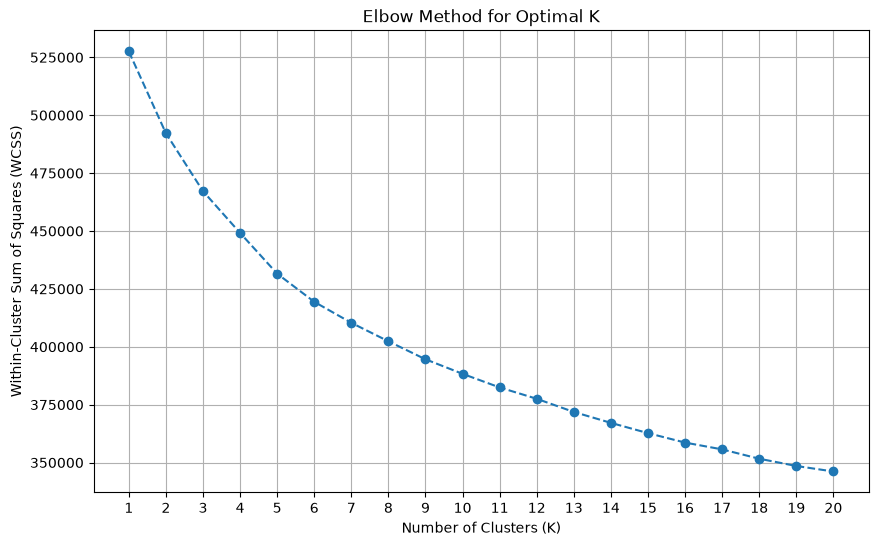

In [8]:
# Determine the optimal number of clusters using the elbow method
wcss = [] # Within-cluster sum of squares
max_clusters = 20 # You can adjust this based on computational resources

print(f"Calculating WCSS for K-Means with 1 to {max_clusters} clusters...")
for i in range(1, max_clusters + 1):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10, max_iter=300, tol=1e-4)
    kmeans.fit(X_subset)
    wcss.append(kmeans.inertia_)

# Plot the elbow curve
plt.figure(figsize=(10, 6))
plt.plot(range(1, max_clusters + 1), wcss, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS)')
plt.xticks(range(1, max_clusters + 1))
plt.grid(True)
plt.show()

 Based on the elbow plot, observe where the decrease in WCSS (Within-Cluster Sum of Squares) starts to slow down significantly, forming an 'elbow'. This point often suggests an appropriate number of clusters. For digit recognition, often 10 clusters (one for each digit 0-9) is expected, but the elbow method helps validate this empirically.

 ### Apply K-Means Clustering with Optimal K

In [9]:
# Choose the optimal number of clusters based on the elbow method (e.g., 10 for digits)
# You might need to adjust this 'optimal_k' based on your elbow plot above.
optimal_k = 10

print(f"Applying K-Means with {optimal_k} clusters...")
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10, max_iter=300, tol=1e-4)
kmeans.fit(X_subset)

# Get cluster labels for the subset data
cluster_labels = kmeans.labels_

print("K-Means clustering complete.")

Applying K-Means with 10 clusters...
K-Means clustering complete.


 ### Analyze Cluster Centroids

Visualizing cluster centroids...


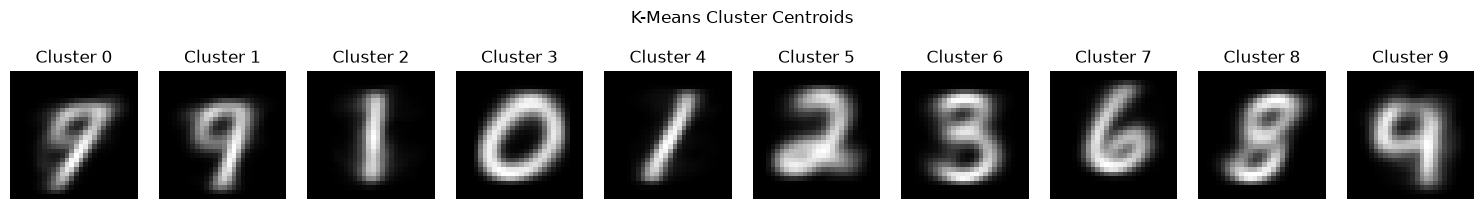

In [10]:
# The cluster centroids represent the 'average' image for each cluster.
# We can visualize these centroids to understand what kind of digits each cluster has grouped together.

print("Visualizing cluster centroids...")
fig, axes = plt.subplots(1, optimal_k, figsize=(optimal_k * 1.5, 2))

for i, ax in enumerate(axes):
    ax.imshow(kmeans.cluster_centers_[i].reshape(28, 28), cmap='gray')
    ax.set_title(f"Cluster {i}")
    ax.axis('off')

plt.suptitle('K-Means Cluster Centroids', y=1.05)
plt.tight_layout(rect=[0, 0.03, 1, 0.98])
plt.show()

 **Interpretation of Centroids:**
Each centroid image shows the average pixel values for all digits assigned to that cluster. By observing these images, we can infer what digit (or type of digit) each cluster primarily represents. For example, a centroid that clearly looks like a '0' suggests that cluster mostly contains '0's.

 #### Distribution of Original Labels within Clusters

Analyzing distribution of original labels within clusters...


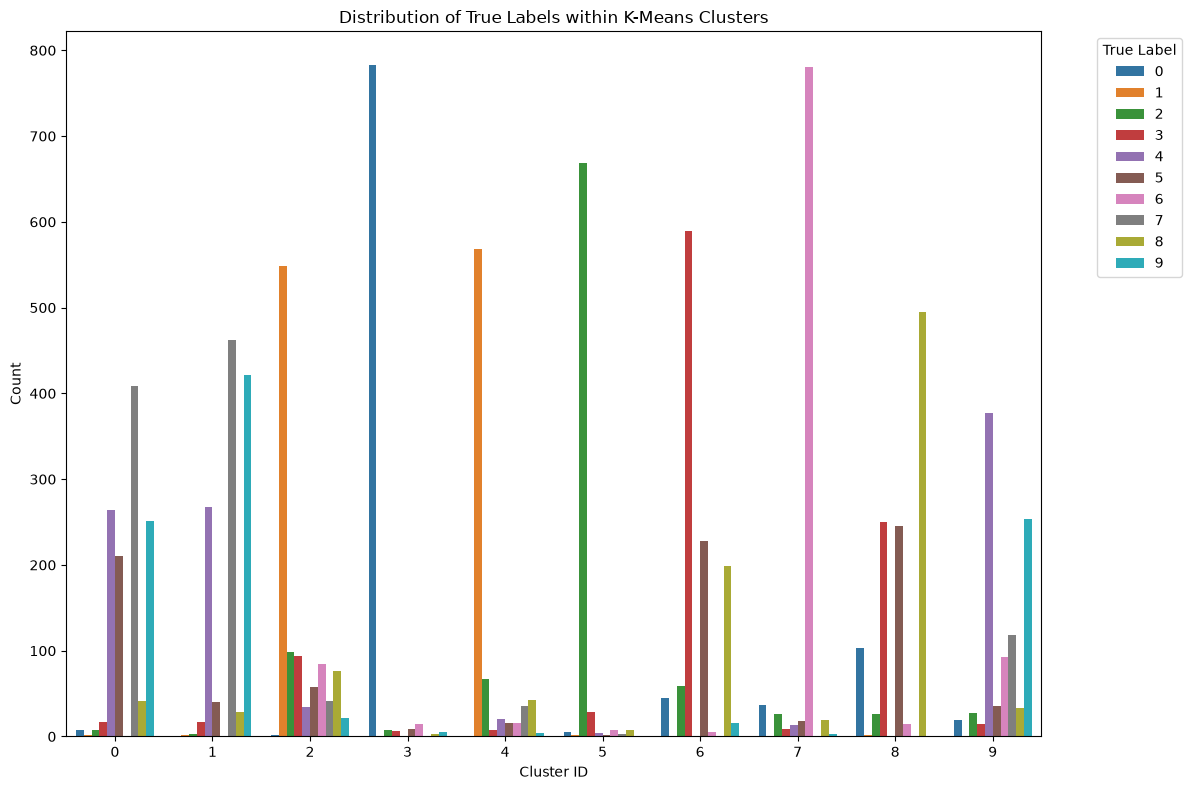

In [11]:
# To further analyze the clusters, let's see the distribution of actual MNIST labels within each cluster.
# This helps in understanding how well the unsupervised clustering aligns with the true labels.

print("Analyzing distribution of original labels within clusters...")
cluster_df = pd.DataFrame({'Cluster': cluster_labels, 'True_Label': y_subset})

plt.figure(figsize=(12, 8))
sns.countplot(data=cluster_df, x='Cluster', hue='True_Label', palette='tab10')
plt.title('Distribution of True Labels within K-Means Clusters')
plt.xlabel('Cluster ID')
plt.ylabel('Count')
plt.legend(title='True Label', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

 ## 3. Model Evaluation and Prediction

 ### Assign Cluster Labels to New Image Data

Predicting cluster labels for 20 new samples...
New Data and Predicted Cluster Labels:


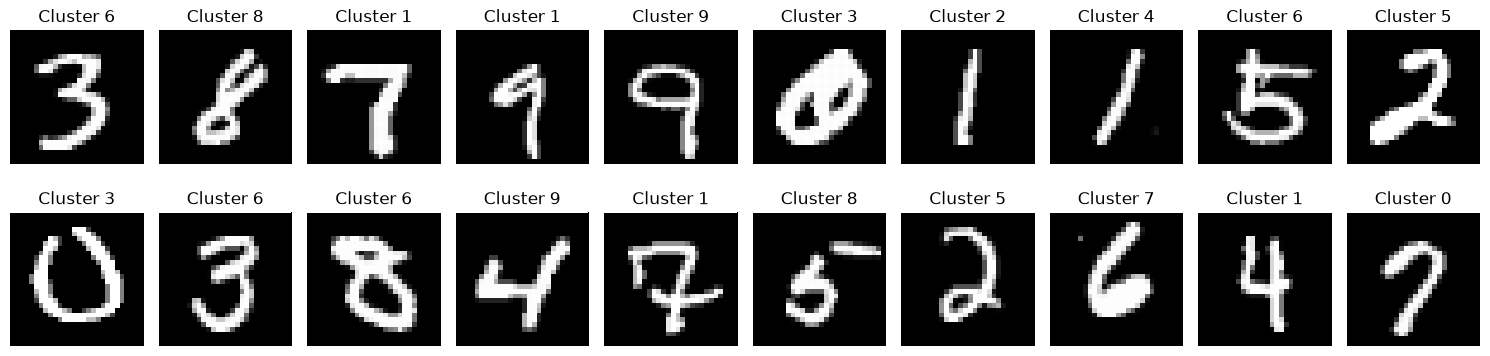

Original labels for these new data points: ['3', '8', '7', '9', '9', ..., '5', '2', '6', '4', '7']
Length: 20
Categories (10, str): ['0', '1', '2', '3', ..., '6', '7', '8', '9']


In [17]:
# The trained K-Means model can be used to predict cluster assignments for new, unseen data.
# We will use a small portion of the data that was NOT part of the `X_subset` used for training.

# Let's take a small sample from the remaining data for demonstration purposes.
# Ensure we don't pick samples that were already used in X_subset.
start_index_for_new_data = n_samples_subset
end_index_for_new_data = n_samples_subset + 20 # Pick 20 new samples

if end_index_for_new_data > len(X_normalized):
    end_index_for_new_data = len(X_normalized)

X_new_data = X_normalized[start_index_for_new_data:end_index_for_new_data]
y_new_data = y[start_index_for_new_data:end_index_for_new_data]

if len(X_new_data) > 0:
    print(f"Predicting cluster labels for {len(X_new_data)} new samples...")
    new_data_cluster_predictions = kmeans.predict(X_new_data)

    # Display the new data and their predicted cluster labels
    print("New Data and Predicted Cluster Labels:")
    fig, axes = plt.subplots(2, 10, figsize=(15, 4))
    for i, ax in enumerate(axes.flat):
        if i < len(X_new_data):
            ax.imshow(X_new_data.iloc[i].to_numpy().reshape(28, 28), cmap='gray')
            ax.set_title(f"Cluster {new_data_cluster_predictions[i]}")
        ax.axis('off')
    plt.tight_layout()
    plt.show()
    print("Original labels for these new data points:", y_new_data.values)
else:
    print("No new data available for prediction after subsetting.")

 ### Validate Model by Analyzing Fit with Existing Clusters

 To validate the clustering model, we can use metrics like the Silhouette Score on the training subset. A higher Silhouette Score indicates better-defined clusters.

In [13]:
# Calculate Silhouette Score for the clustered subset
# This score measures how similar an object is to its own cluster (cohesion)
# compared to other clusters (separation).

print("Calculating Silhouette Score...")
silhouette_avg = silhouette_score(X_subset, cluster_labels)
print(f"The average Silhouette Score for the clusters is: {silhouette_avg:.3f}")

# Note: Silhouette score can be computationally intensive for very large datasets.
# A value closer to 1 indicates that samples are well-matched to their own cluster and poorly matched to neighboring clusters.
# A value near 0 indicates overlapping clusters.
# A value near -1 indicates that samples might have been assigned to the wrong clusters.

Calculating Silhouette Score...
The average Silhouette Score for the clusters is: 0.061


 We can also re-evaluate the purity of our clusters by examining the distribution of true labels within the predicted clusters for the *entire* original dataset (or a larger portion if `X_subset` was very small). For simplicity, let's look at the purity on `X_subset` again, but this time explicitly discussing it as validation.

Cluster Purity (Count of True Labels per Cluster):
True Label    0    1    2    3    4    5    6    7    8    9
Cluster                                                     
0             7    2    8   17  264  211    0  409   41  251
1             0    2    3   17  268   40    0  462   29  422
2             2  549   99   94   34   58   84   41   76   22
3           783    0    7    6    0    9   14    1    3    5
4             0  568   67    7   20   16   16   35   42    4
5             5    2  669   28    4    2    8    3    7    0
6            45    1   59  589    0  228    5    1  199   16
7            37    0   26    9   13   18  780    0   19    3
8           103    2   26  250    0  246   14    0  495    1
9            19    1   27   15  377   35   93  118   33  254


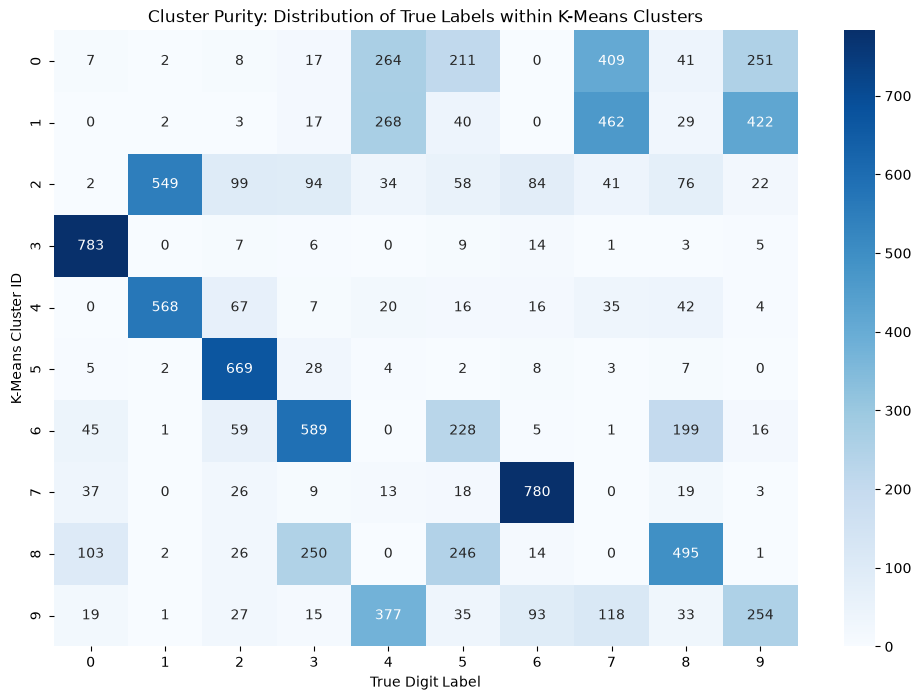

In [14]:
# Re-examining the distribution of true labels within the clusters (for X_subset)
# This helps assess the 'purity' of each cluster with respect to the known digit labels.

cluster_true_label_counts = pd.crosstab(index=cluster_labels, columns=y_subset, rownames=['Cluster'], colnames=['True Label'])
print("Cluster Purity (Count of True Labels per Cluster):")
print(cluster_true_label_counts)

# Visualize the purity again for clearer interpretation if needed
plt.figure(figsize=(12, 8))
sns.heatmap(cluster_true_label_counts, annot=True, fmt='d', cmap='Blues')
plt.title('Cluster Purity: Distribution of True Labels within K-Means Clusters')
plt.xlabel('True Digit Label')
plt.ylabel('K-Means Cluster ID')
plt.show()

 ## 4. Dimensionality Reduction and Visualization

 ### Principal Component Analysis (PCA)

 PCA is a linear dimensionality reduction technique that transforms the data to a new coordinate system such that the greatest variance by any projection lies on the first principal component, the second greatest variance on the second principal component, and so on. We'll use it to reduce the 784 dimensions to 2 for visualization.

Applying PCA for 2 components...
Shape after PCA: (10000, 2)


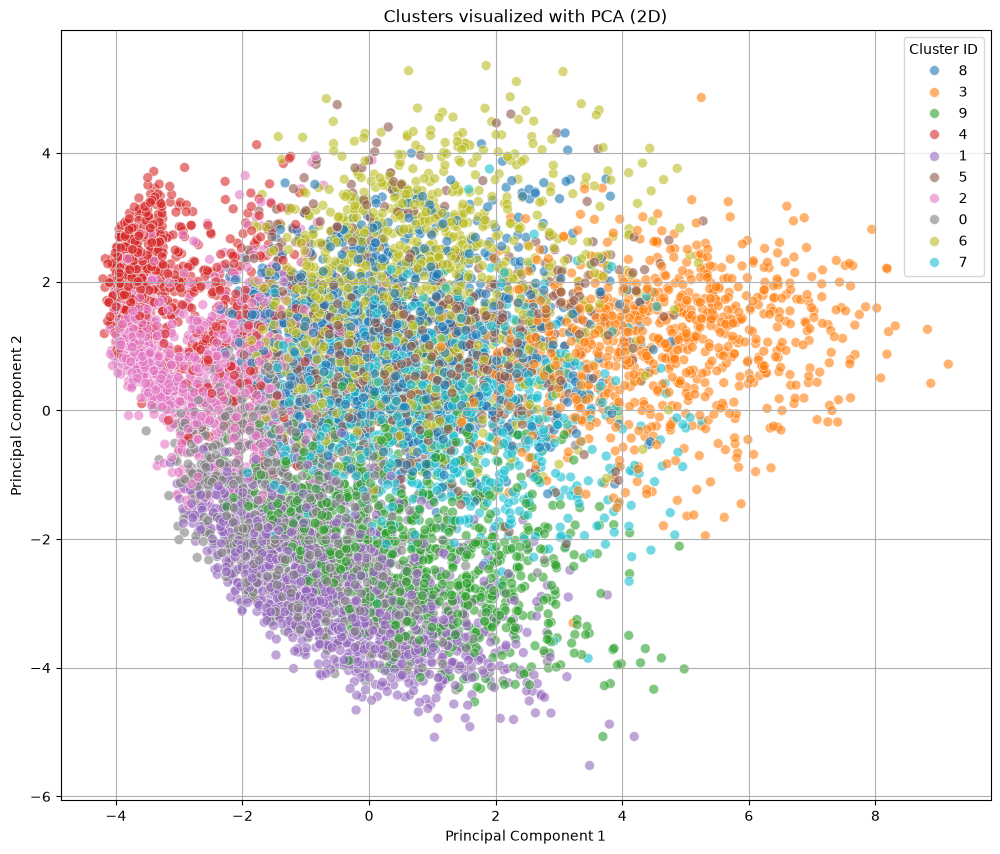

In [15]:
# Apply PCA to reduce dimensions to 2 for visualization
# We'll use the X_subset (normalized data) and its cluster_labels

print("Applying PCA for 2 components...")
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_subset)

print(f"Shape after PCA: {X_pca.shape}")

# Visualize the clusters in 2D using PCA
plt.figure(figsize=(12, 10))
sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1],
    hue=cluster_labels.astype(str),
    palette='tab10', s=50, alpha=0.6
)
plt.title('Clusters visualized with PCA (2D)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster ID')
plt.grid(True)
plt.show()

 ### t-Distributed Stochastic Neighbor Embedding (t-SNE)

 t-SNE is a non-linear dimensionality reduction technique well-suited for visualizing high-dimensional datasets. It attempts to preserve local structures within the data, making it effective for revealing natural clusters. Due to its computational intensity, we'll apply it to a smaller sample of the subset.

Applying t-SNE on a sample of 2000 points...
[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 2000 samples in 0.010s...
[t-SNE] Computed neighbors for 2000 samples in 0.211s...
[t-SNE] Computed conditional probabilities for sample 1000 / 2000
[t-SNE] Computed conditional probabilities for sample 2000 / 2000
[t-SNE] Mean sigma: 2.512582
[t-SNE] KL divergence after 250 iterations with early exaggeration: 74.207893
[t-SNE] KL divergence after 1000 iterations: 1.153312
Shape after t-SNE: (2000, 2)


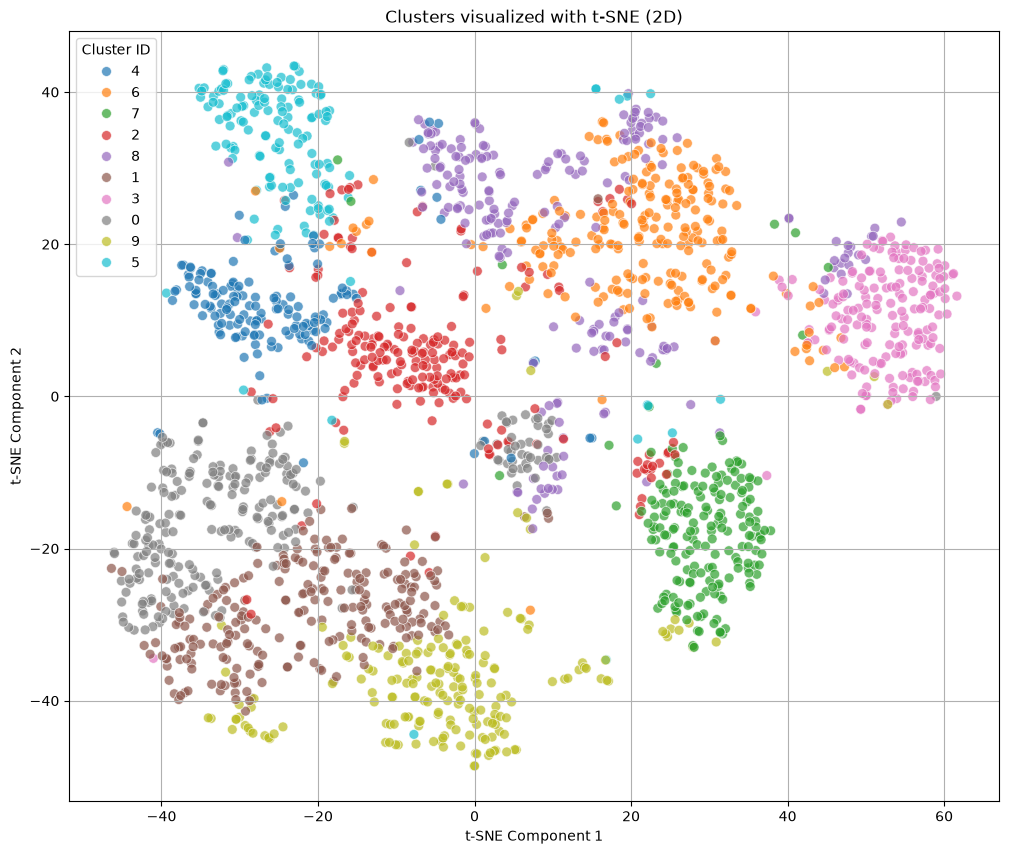

In [19]:
# Due to t-SNE's computational cost, let's sample a smaller portion of the subset for visualization.
# For example, take 2000 samples from X_subset.

n_tsne_samples = 2000
np.random.seed(42)
tsne_indices = np.random.choice(len(X_subset), n_tsne_samples, replace=False)

X_tsne_sample = X_subset.iloc[tsne_indices]
cluster_labels_tsne_sample = cluster_labels[tsne_indices]

print(f"Applying t-SNE on a sample of {n_tsne_samples} points...")
tsne = TSNE(n_components=2, random_state=42, verbose=1, perplexity=30, max_iter=1000)
X_tsne = tsne.fit_transform(X_tsne_sample)

print(f"Shape after t-SNE: {X_tsne.shape}")

# Visualize the clusters in 2D using t-SNE
plt.figure(figsize=(12, 10))
sns.scatterplot(
    x=X_tsne[:, 0], y=X_tsne[:, 1],
    hue=cluster_labels_tsne_sample.astype(str),
    palette='tab10', s=50, alpha=0.7
)
plt.title('Clusters visualized with t-SNE (2D)')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.legend(title='Cluster ID')
plt.grid(True)
plt.show()

 **Insights from Visualization:**
*   **PCA:** Provides a global view of variance. Clusters might be less distinctly separated due to its linear nature.
*   **t-SNE:** Often produces more visually distinct clusters, highlighting local relationships. This plot helps to assess how well the K-Means algorithm separated the different digit groups in a non-linear fashion.